# Jakobshavn Isbræ TerraSAR-X Velocities, October 2022 – October 2026 (NSIDC-0481)
---

This notebook unpacks, reads and plots the TerraSAR-X/TanDEM-X (TSX) velocity maps for the Jakobshavn Isbræ grid
**W69.10N** from the MEaSUREs *Greenland Ice Velocity: Selected Glacier Site Velocity Maps from InSAR* data set
([NSIDC-0481](https://nsidc.org/data/NSIDC-0481)). The data come as two tar files, each containing one directory per
image pair (`Vel.<first date>.<second date>`):

- `Version4-update-through-December2024_Wcoast-69.10N.tar`: 71 Version 4 maps, October 2022 – January 2025, and
- `Version5-update-through-October2026_Wcoast-69.10N.tar`: 42 Version 5 maps, January 2025 – October 2026.

Version 5 starts with pairs whose first image was acquired on or after 5 January 2025. The two versions are directly
comparable (the processing of a single image pair is the same), and the maps share the same grid, so they are treated as
one series here. Earlier maps (2008–2023) are available from NSIDC; see `JakobshavnTSXFullSeries.ipynb`.

Each map has the velocity components (`vx`, `vy`), the speed (`vv`) and the component errors (`ex`, `ey`) as cloud-optimized
GeoTIFFs in polar stereographic coordinates (EPSG:3413) at 100 m posting, plus a browse JPEG and a `.meta` file with
the acquisition details. The products are read with the `nisarVel` and `nisarVelSeries` classes from
[nisardev](https://github.com/fastice/nisardev), as in the other [GrIMP notebooks](https://github.com/fastice/GrIMPNotebooks).

## Environment Setup

The notebook needs `nisardev` and its dependencies. The simplest setup is the GrIMP notebook environment
(`binder/environment.yml` in the [GrIMPNotebooks](https://github.com/fastice/GrIMPNotebooks) repository):

`conda env create -f binder/environment.yml`

`conda activate greenlandMapping`

`python -m ipykernel install --user --name=greenlandMapping`

`jupyter lab`

Put this notebook in the same directory as the tar files and their `.manifest` files. No login is needed, since all of
the data are local.

## Python Setup

In [1]:
import nisardev as nisar
import os
import glob
import hashlib
import tarfile
import numpy as np
import pyproj
import matplotlib.pyplot as plt
from datetime import datetime

## Unpack the Data

Each tar file unpacks to a directory named after its release, e.g. `Version5-update-through-October2026/Wcoast-69.10N/`.
The next cells only unpack a tar file if that has not already been done: they check that every file in the tar already
exists on disk with the right size. When a tar file is unpacked, it is first checked against the MD5 checksum in its
`.manifest` file.

In [2]:
tarFiles = ['Version4-update-through-December2024_Wcoast-69.10N.tar',
            'Version5-update-through-October2026_Wcoast-69.10N.tar']
dataDir = '.'  # unpack next to the tar files

In [3]:
def alreadyUnpacked(tarFile, dataDir):
    ''' True if every file in tarFile already exists in dataDir with the same size '''
    with tarfile.open(tarFile) as tf:
        members = [m for m in tf.getmembers() if m.isfile()]
    for m in members:
        path = os.path.join(dataDir, m.name)
        if not os.path.exists(path) or os.path.getsize(path) != m.size:
            return False, len(members)
    return True, len(members)


def checkManifest(tarFile, manifestFile):
    ''' Compare the tar file's MD5 checksum with the one in the manifest '''
    with open(manifestFile) as fp:
        manifest = dict(line.strip().split('=', 1) for line in fp if '=' in line)
    md5 = hashlib.md5()
    with open(tarFile, 'rb') as fp:
        for block in iter(lambda: fp.read(2**20), b''):
            md5.update(block)
    if md5.hexdigest() != manifest['MD5 Checksum']:
        raise ValueError(f'{tarFile} MD5 {md5.hexdigest()} does not match the manifest')
    print(f'{tarFile}: MD5 matches the manifest')


for tarFile in tarFiles:
    unpacked, nFiles = alreadyUnpacked(tarFile, dataDir)
    if unpacked:
        print(f'{tarFile}: all {nFiles} files are already unpacked, skipping')
    else:
        checkManifest(tarFile, tarFile.replace('.tar', '.manifest'))
        with tarfile.open(tarFile) as tf:
            tf.extractall(dataDir, filter='data')
        print(f'{tarFile}: unpacked {nFiles} files into {os.path.abspath(dataDir)}')

Version4-update-through-December2024_Wcoast-69.10N.tar: all 639 files are already unpacked, skipping
Version5-update-through-October2026_Wcoast-69.10N.tar: all 378 files are already unpacked, skipping


## Locate the Products

The read routines take one name per product with a wildcard (`*`) in place of the band (`vx`, `vy`, `vv`, `ex`, `ey`) and no
`.tif` extension, e.g. `TSX_W69.10N_05Jan25_16Jan25_20-42-36_*_v05.0`. The dates are parsed from the file names. The
products of both releases are collected and sorted by date (the `Vel.<first date>.<second date>` directory name).

In [4]:
vvFiles = sorted(glob.glob(f'{dataDir}/Version*-update-through-*/Wcoast-69.10N/Vel.*/*_vv_v0?.0.tif'),
                 key=lambda f: os.path.basename(os.path.dirname(f)))
myTiffs = [f.replace('_vv_', '_*_').replace('.tif', '') for f in vvFiles]
for version in ['v04.0', 'v05.0']:
    print(f'{version}: {sum(version in t for t in myTiffs)} products')
print(f'first: {os.path.basename(myTiffs[0])}')
print(f'last:  {os.path.basename(myTiffs[-1])}')

v04.0: 71 products
v05.0: 42 products
first: TSX_W69.10N_31Oct22_11Nov22_20-33-57_*_v04.0
last:  TSX_W69.10N_24Sep26_05Oct26_20-42-48_*_v05.0


## A Single Map: nisarVel

A `nisarVel` instance holds one velocity map. Here the first map is read and displayed (`readSpeed=False` computes the
speed from the components instead of reading the `vv` file). For a single map the positions of the two dates in the
`_`-separated file name (`index1`, `index2`) must be given for TSX names; the series reader below finds them itself.

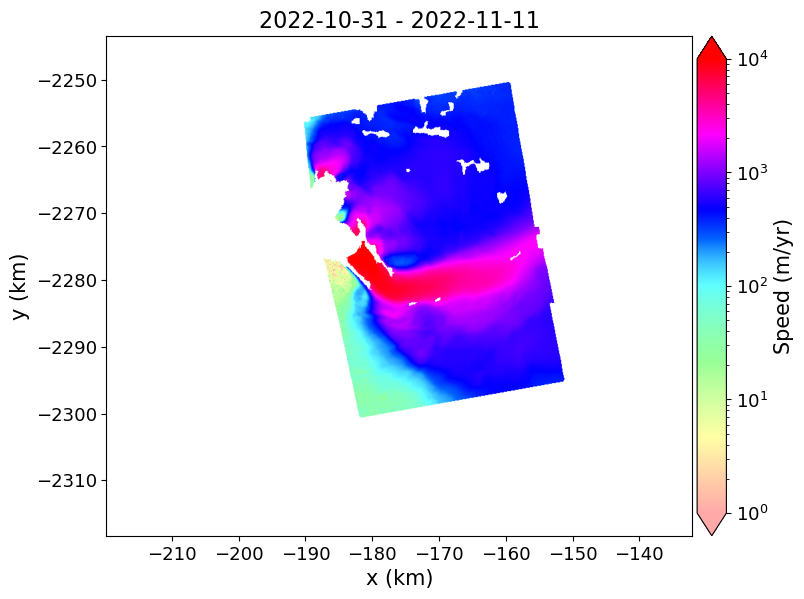

In [5]:
myVel = nisar.nisarVel()
myVel.readDataFromTiff(myTiffs[0], url=False, readSpeed=False, index1=2, index2=3)
fig, ax = plt.subplots(1, 1, figsize=(8, 7))
myVel.displayVel(ax=ax, units='km', vmin=1, vmax=10000, scale='log', midDate=False)

## All Maps: nisarVelSeries

A `nisarVelSeries` holds any number of maps with the same grid, which is the case for all of the products for one TSX
box, in either version. `useErrors=True` also reads the `ex` and `ey` error estimates. `loadRemote()` reads the data into memory (for local
files it simply avoids repeated reads from disk).

In [6]:
jakSeries = nisar.nisarVelSeries()
jakSeries.readSeriesFromTiff(myTiffs, url=False, readSpeed=False, useErrors=True)
jakSeries.loadRemote()
print(f'{len(jakSeries.time)} maps, {jakSeries.time[0]:%Y-%m-%d} to {jakSeries.time[-1]:%Y-%m-%d} (mid dates)')
print('Bounding box (m):', jakSeries.boundingBox())

113 maps, 2022-11-05 to 2026-09-29 (mid dates)
Bounding box (m): {'minx': -219800.0, 'maxx': -132100.0, 'miny': -2318300.0, 'maxy': -2243500.0}


Six of the maps, spread through the series, show the seasonal speed-up and slow-down near the terminus:

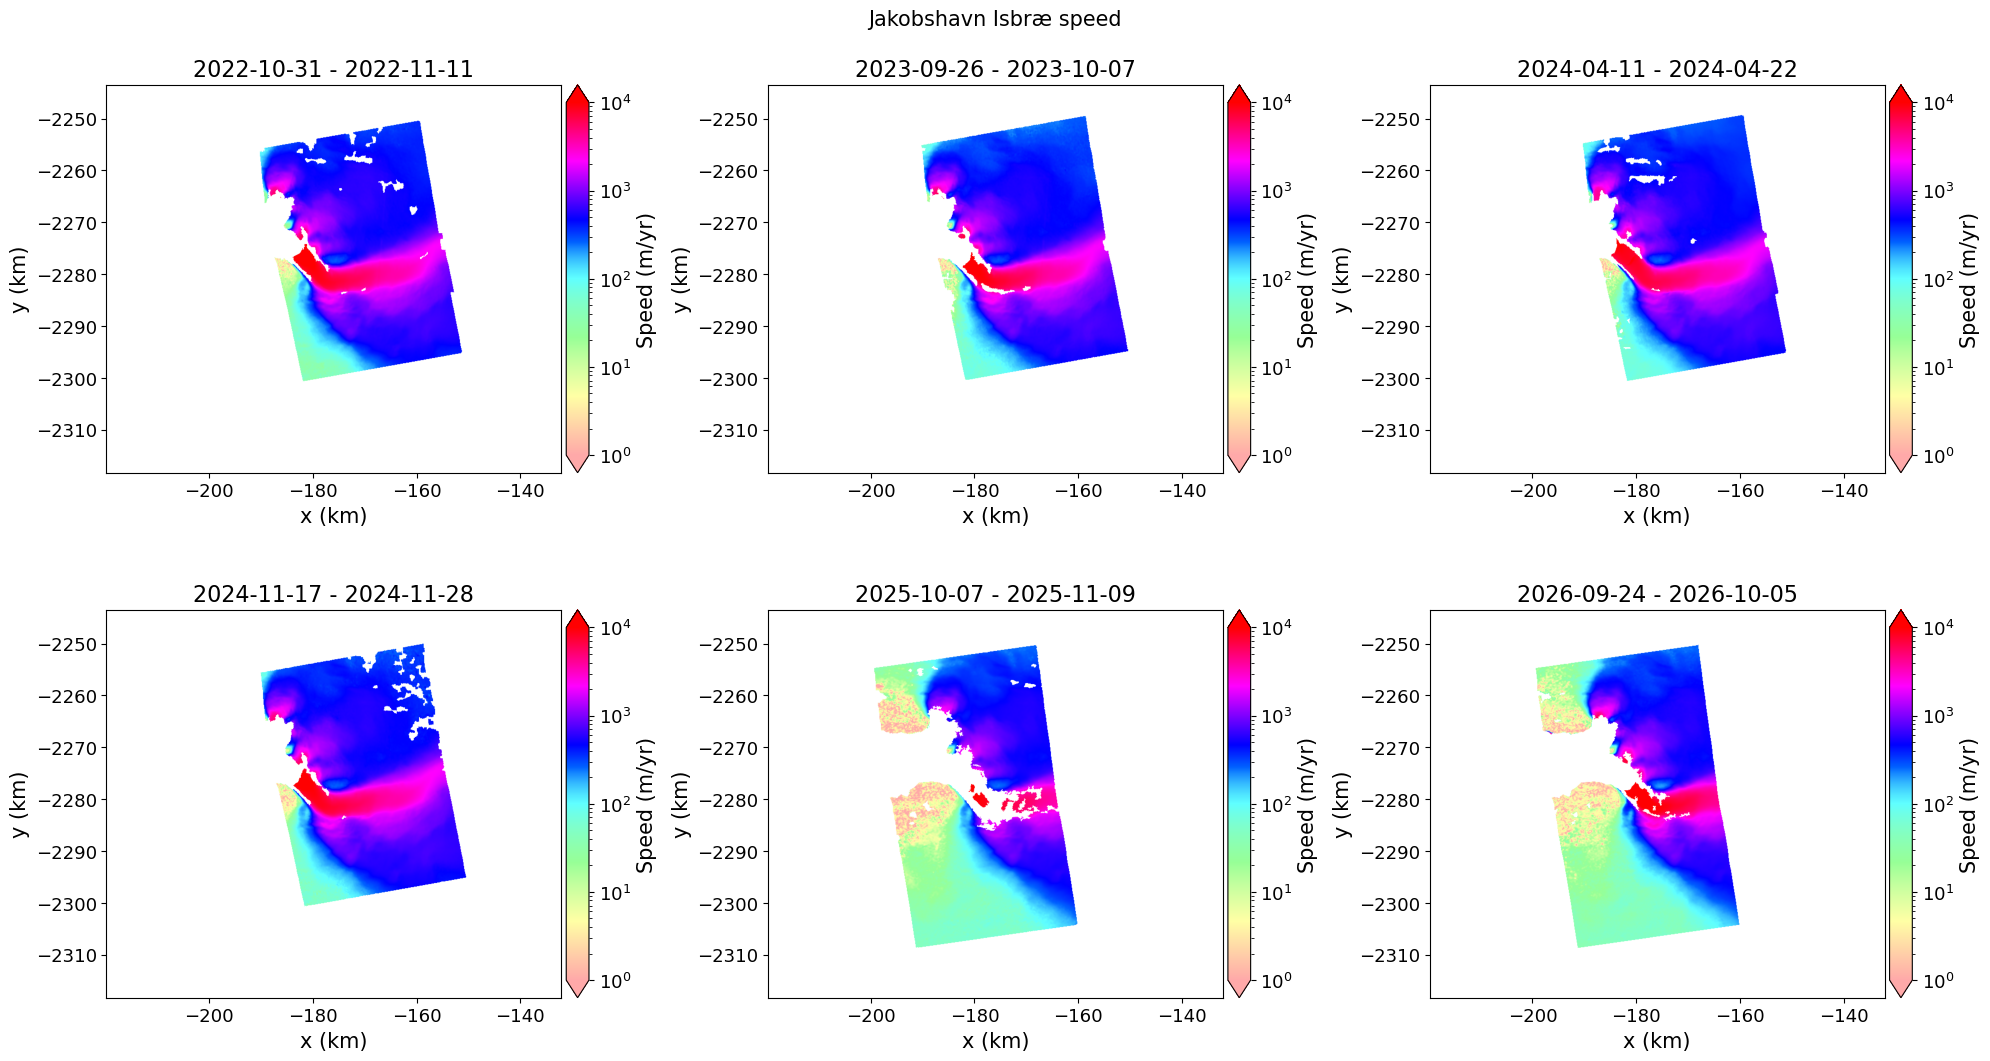

In [7]:
dates = [jakSeries.time[i] for i in np.linspace(0, len(jakSeries.time) - 1, 6).astype(int)]
fig, axes = plt.subplots(2, 3, figsize=(20, 11))
for date, ax in zip(dates, axes.flatten()):
    jakSeries.displayVelForDate(date=date, band='vv', ax=ax, units='km', vmin=1, vmax=10000, scale='log',
                                midDate=False)
fig.suptitle('Jakobshavn Isbræ speed', fontsize=15)
fig.tight_layout()

## Sample Points

Four numbered sample points, given as latitude/longitude: two on the main trunk, one on the northern branch and one on
slower ice at the southern margin. The first is the
point used for the Jakobshavn time series in Figure 1 of the 2023 DLR TSX summary (x, y = -180.6, -2278.6 km), near the
terminus. They are converted to polar stereographic x/y (EPSG:3413) to plot them on the map.

In [8]:
points = {'Lower trunk (DLR 2023 Fig. 1)': (69.1243, -49.5317),
          'Upper trunk': (69.1191, -49.2642),
          'Northern branch': (69.2371, -49.5418),
          'Southern margin': (69.0246, -49.4446)}
lat, lon = np.array(list(points.values())).transpose()
xPts, yPts = pyproj.Transformer.from_crs(4326, 3413).transform(lat, lon)
colors = ['r', 'm', 'c', 'darkorange']

The mean speed and the number of valid maps at each pixel, with the points:

self.var [np.str_('vx'), np.str_('vy'), np.str_('vv'), np.str_('ex'), np.str_('ey'), np.str_('ev')]
self.var [np.str_('vx'), np.str_('vy'), np.str_('vv'), np.str_('ex'), np.str_('ey'), np.str_('ev')]
self.var [np.str_('vx'), np.str_('vy'), np.str_('vv'), np.str_('ex'), np.str_('ey'), np.str_('ev')]


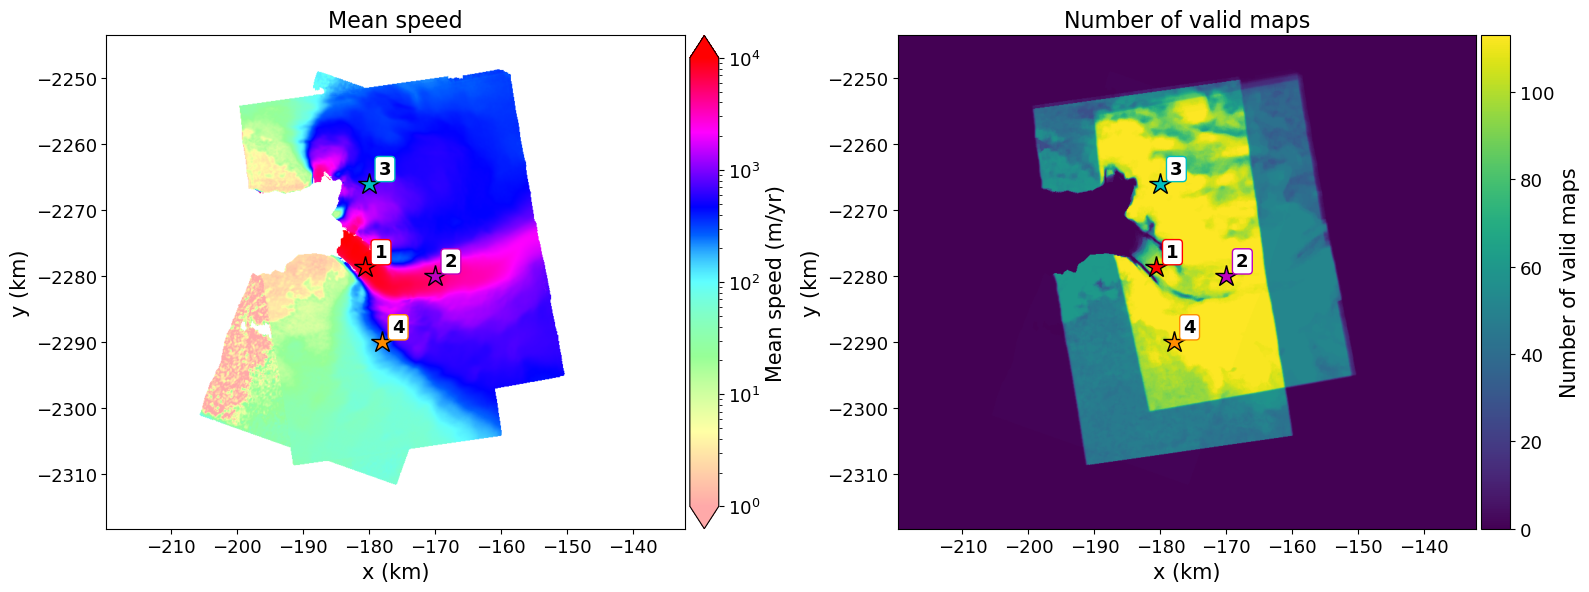

In [9]:
velMean = jakSeries.mean()
velCount = jakSeries.numberValid()
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
velMean.displayVelForDate(ax=axes[0], units='km', vmin=1, vmax=10000, scale='log', colorBarLabel='Mean speed (m/yr)',
                          title='Mean speed')
velCount.displayVelForDate(ax=axes[1], units='km', vmin=0, vmax=len(jakSeries.time), autoScale=False,
                           colorBarLabel='Number of valid maps', extend='neither', title='Number of valid maps')
for ax in axes:
    for k, (x, y, c) in enumerate(zip(xPts, yPts, colors)):
        ax.plot(x / 1000, y / 1000, '*', color=c, markersize=16, markeredgecolor='k')
        ax.annotate(str(k + 1), (x / 1000, y / 1000), xytext=(7, 7), textcoords='offset points', fontsize=13,
                    fontweight='bold', bbox=dict(boxstyle='round,pad=0.2', fc='white', ec=c))
fig.tight_layout()

`interp` samples every map at the points. Passing `sourceEPSG=4326` lets it take the latitude/longitude directly, and
`returnXR=True` returns an Xarray with a `band` and a `time` dimension.

In [10]:
vPts = jakSeries.interp(lat, lon, sourceEPSG=4326, returnXR=True)
vPts

<xarray.DataArray 'VelocityMap' (band: 6, time: 113, dim_0: 4)> Size: 22kB
array([[[-7.07828933e+03, -4.98681412e+03, -5.31971071e+02,
         -1.05684267e+02],
        [-6.91778638e+03, -5.00317107e+03, -4.85341825e+02,
         -1.58669305e+02],
        [-6.16339723e+03, -4.77787099e+03, -4.98730720e+02,
         -1.37443632e+02],
        ...,
        [-1.14911940e+04, -6.58581227e+03, -4.85404630e+02,
         -1.38840483e+02],
        [-1.12312174e+04, -6.47183441e+03, -4.84486685e+02,
         -1.37757109e+02],
        [-1.06186283e+04, -6.36608906e+03, -4.70639526e+02,
         -1.31543956e+02]],

       [[ 6.68432794e+03, -1.62293142e+03, -5.56624454e+02,
          1.84580477e+02],
        [ 6.57368210e+03, -1.60767748e+03, -5.37598365e+02,
          1.86475341e+02],
        [ 5.84395495e+03, -1.52910829e+03, -5.30128545e+02,
          1.93857174e+02],
...
        [ 1.26873541e+01,  9.03812548e+00,  2.92537776e+00,
          1.25243770e+01],
        [ 1.01248481e+01,  8.02403127e+00,  3.18426898e+00,
          3.24085768e+00],
        [ 1.27038064e+01,  1.03343173e+01,  3.16221008e+00,
          2.59803161e+00]],

       [[ 9.63676038e+00,  4.48588125e+00,  3.20929012e+00,
          1.64948834e+00],
        [ 9.21764389e+00,  4.83908987e+00,  3.93651005e+00,
          1.93575305e+00],
        [ 8.58364861e+00,  5.17368219e+00,  3.05808994e+00,
          1.38132676e+00],
        ...,
        [ 1.32441502e+01,  9.22424336e+00,  3.35786482e+00,
          1.00579856e+01],
        [ 1.23221333e+01,  7.79853648e+00,  3.58231926e+00,
          2.94743271e+00],
        [ 1.34109850e+01,  8.52570206e+00,  3.89646295e+00,
          2.44101961e+00]]])
Coordinates:
  * time         (time) datetime64[ns] 904B 2022-11-05T12:00:00 ... 2026-09-2...
  * band         (band) <U2 48B 'vx' 'vy' 'vv' 'ex' 'ey' 'ev'
    name         <U4 16B 'None'
    _FillValue   (band) float64 48B -2e+09 -2e+09 -1.0 -2e+09 -2e+09 -1.0
    spatial_ref  int64 8B 0
    time1        (time) datetime64[ns] 904B 2022-10-31 2022-11-11 ... 2026-09-24
    time2        (time) datetime64[ns] 904B 2022-11-11 2022-11-22 ... 2026-10-05
    x            (dim_0) float64 32B -1.806e+05 -1.7e+05 -1.8e+05 -1.78e+05
    y            (dim_0) float64 32B -2.279e+06 -2.28e+06 -2.266e+06 -2.29e+06
Dimensions without coordinates: dim_0

The error estimates are given for the x and y components. The error in speed follows from propagating them through
$v = \sqrt{v_x^2 + v_y^2}$, assuming the component errors are uncorrelated:

$$\sigma_v = \frac{\sqrt{v_x^2 e_x^2 + v_y^2 e_y^2}}{v}$$

i.e. the component errors projected onto the flow direction. Note this is not $\sqrt{e_x^2 + e_y^2}$, which is the length of
the error vector.

In [11]:
vx, vy, vv = (vPts.sel(band=b).values for b in ['vx', 'vy', 'vv'])
ex, ey = (vPts.sel(band=b).values for b in ['ex', 'ey'])
ev = np.sqrt((vx * ex)**2 + (vy * ey)**2) / vv

The speed time series at each point, with the speed errors as error bars (each value is plotted at the middle date of its
image pair). Version 4 maps are plotted as filled symbols and Version 5 maps as open symbols; the dotted line marks
5 January 2025, where Version 5 begins.

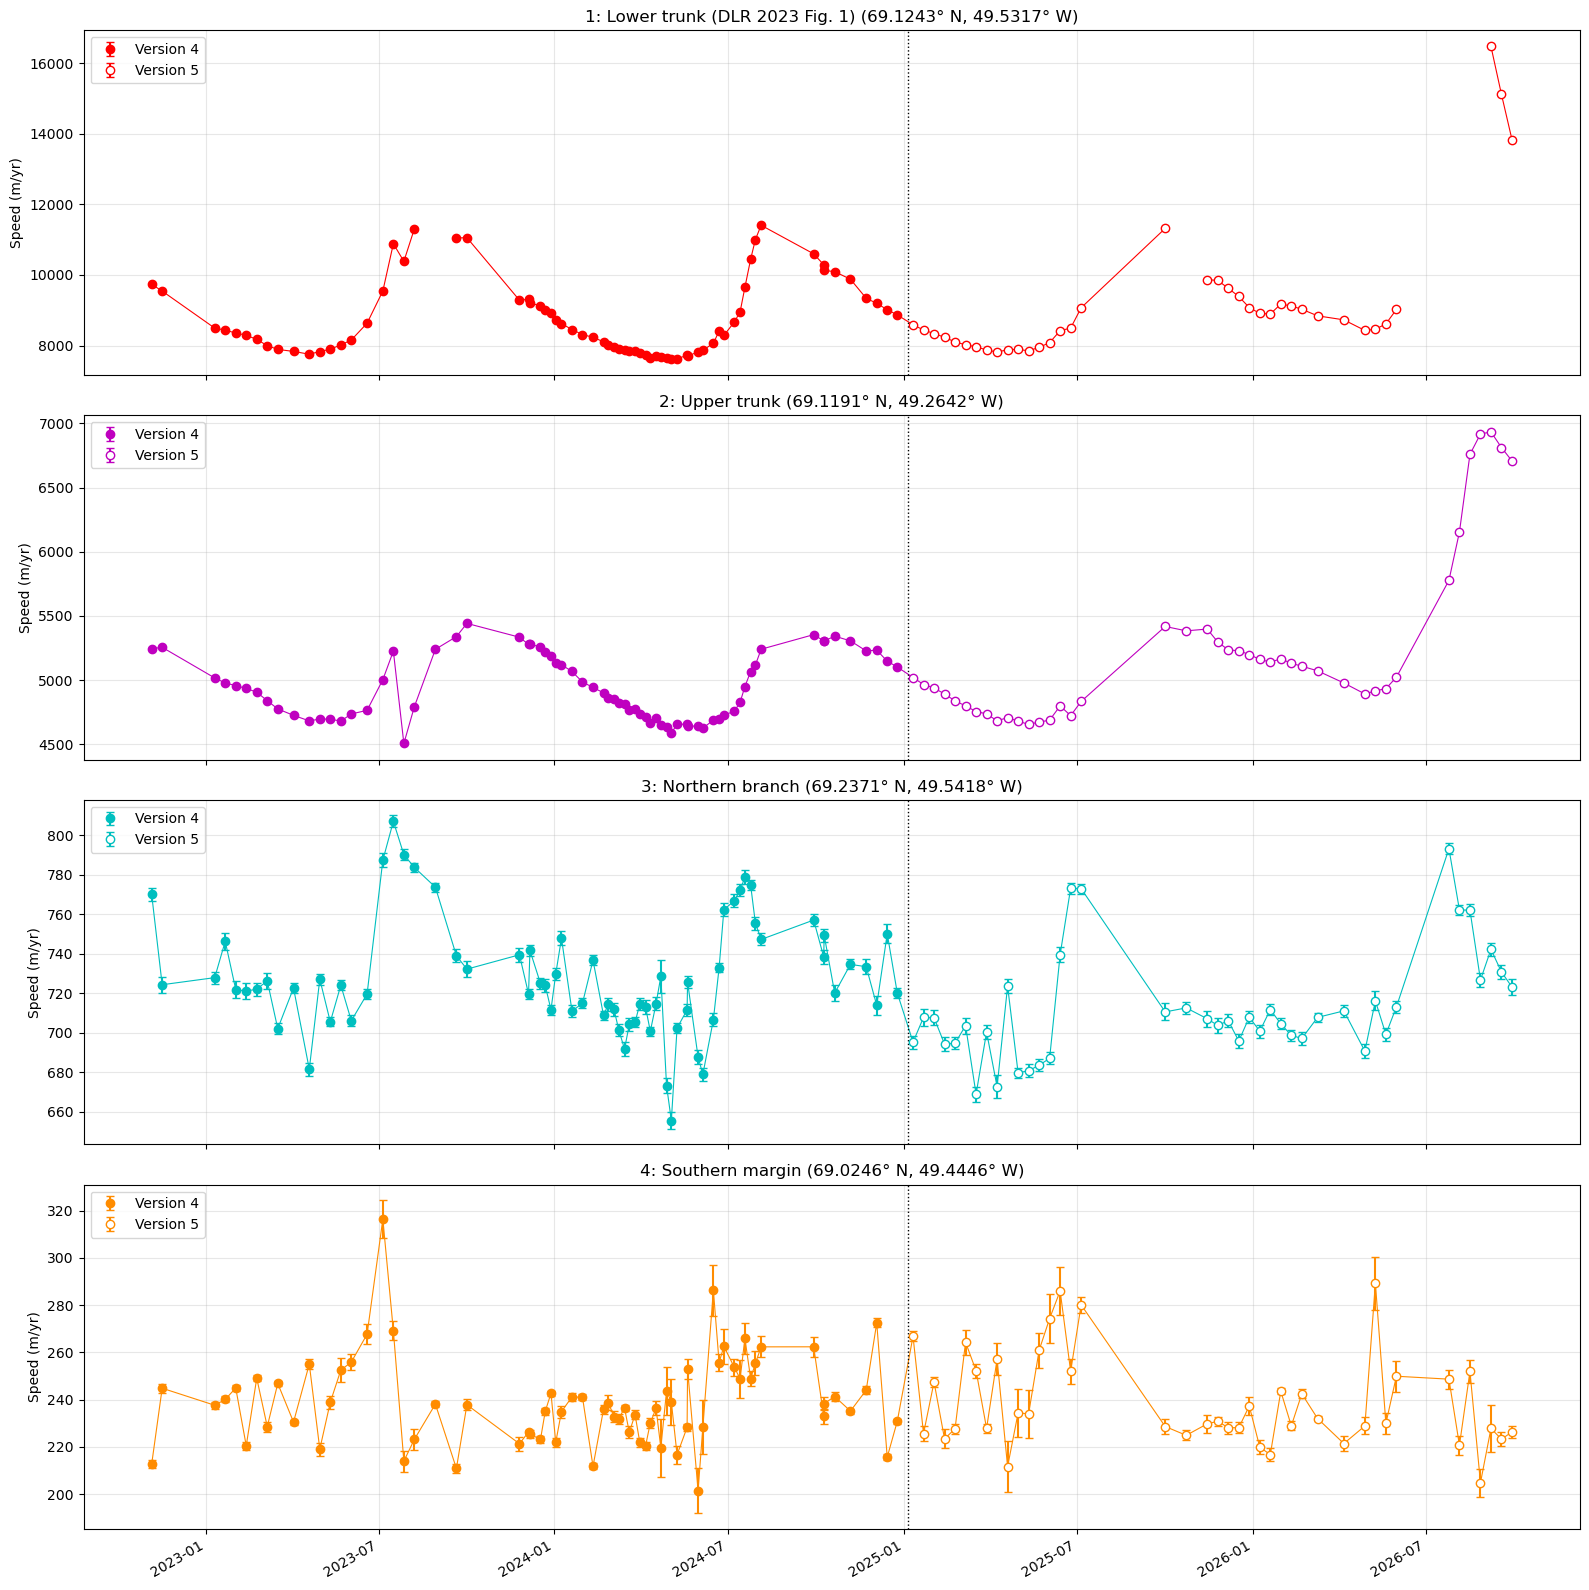

In [12]:
times = np.array(jakSeries.time)
isV5 = times >= datetime(2025, 1, 5)
fig, axes = plt.subplots(4, 1, figsize=(16, 16), sharex=True)
for i, (name, ax, c) in enumerate(zip(points, axes.flatten(), colors)):
    ax.plot(times, vv[:, i], '-', color=c, linewidth=0.8)
    ax.errorbar(times[~isV5], vv[~isV5, i], yerr=ev[~isV5, i], fmt='o', color=c, capsize=3, label='Version 4')
    ax.errorbar(times[isV5], vv[isV5, i], yerr=ev[isV5, i], fmt='o', color=c, markerfacecolor='white', capsize=3,
                label='Version 5')
    ax.axvline(datetime(2025, 1, 5), color='k', linestyle=':', linewidth=1)
    ax.legend(loc='upper left')
    ax.set_title(f'{i + 1}: {name} ({lat[i]:.4f}° N, {-lon[i]:.4f}° W)')
    ax.set_ylabel('Speed (m/yr)')
    ax.grid(True, alpha=0.3)
fig.autofmt_xdate()
fig.tight_layout()

Most maps have errors of a few to a few tens of m/yr, small compared with the seasonal changes. Gaps are pairs with no valid
data at that point. Point 1 is close to the calving front, so it is missing when the front retreats past it in late summer,
and the fastest values there come from the weeks just before or after the retreat.

## Saving the Data

The series can be saved to a single NetCDF file and reloaded later without the individual GeoTIFFs:

In [13]:
jakSeries.toNetCDF('JakobshavnTSX.nc')
jakReload = nisar.nisarVelSeries()
jakReload.readSeriesFromNetCDF('JakobshavnTSX.nc')
print(f'Reloaded {len(jakReload.time)} maps')
os.remove('JakobshavnTSX.nc')  # comment out this line to keep the file

Reloaded 113 maps
